## Setup

In [1]:
!pip install -q tqdm

In [2]:
import os, re, hashlib, zipfile, requests, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 200)

DATA_DIR = '/content/data'
ROOT = os.path.join(DATA_DIR, 'Pakistan Sign Language Urdu Alphabets')
OUT = '/content/outputs'
IMG_OUT = os.path.join(OUT, 'images')
os.makedirs(IMG_OUT, exist_ok=True)

# Re-download only if the Colab runtime was reset
if not os.path.isdir(ROOT):
    ZIP_PATH = '/content/ualpha40.zip'
    URL = 'https://data.mendeley.com/public-api/zip/3pvnnckxyb/download/1'
    if not os.path.exists(ZIP_PATH):
        with requests.get(URL, stream=True) as r:
            r.raise_for_status()
            with open(ZIP_PATH, 'wb') as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
print('Dataset root exists:', os.path.isdir(ROOT))

cleaning_log = []   # (step, issue, count, action)
def log(step, issue, count, action):
    cleaning_log.append({'step': step, 'issue': issue, 'count': int(count), 'action': action})

Dataset root exists: True


## 1. Build the metadata table
One row per file. The label is the **folder name**. We also parse the filename, which looks like `s0254-38hamza-Generated-640.jpg`:
`subject id` – `class number + class name` – optional `Generated-N` (augmented copy).

In [3]:
rows = []
for cls in sorted(os.listdir(ROOT)):
    folder = os.path.join(ROOT, cls)
    if not os.path.isdir(folder):
        continue
    for fn in os.listdir(folder):
        p = os.path.join(folder, fn)
        rows.append({'rel_path': os.path.join(cls, fn), 'path': p, 'label': cls, 'filename': fn,
                     'ext_raw': os.path.splitext(fn)[1]})
meta = pd.DataFrame(rows)
meta['ext'] = meta['ext_raw'].str.lower()
meta['media_type'] = meta['ext'].map({'.jpg': 'image', '.jpeg': 'image', '.png': 'image', '.mp4': 'video'})

pat = re.compile(r'^(?P<subject>s\d+)-(?P<num>\d+)(?P<name>[A-Za-z]+)(?:-Generated-(?P<gen>\d+))?\.\w+$', re.I)
parsed = meta['filename'].str.extract(pat)
meta['subject'] = parsed['subject']
meta['name_in_file'] = parsed['num'].fillna('') + parsed['name'].fillna('').str.lower()
meta['class_num_in_file'] = parsed['num']
meta['is_generated'] = parsed['gen'].notna()
meta['name_matched'] = parsed['subject'].notna()

print(meta.shape)
meta['media_type'].value_counts(dropna=False)

(23258, 12)


,count
media_type,
image,22865
video,393


## 2. Missing values

In [4]:
# 2a. Missing values in the parsed metadata
print(meta[['subject', 'class_num_in_file', 'media_type']].isna().sum())

# 2b. Zero-byte files
meta['size_bytes'] = meta['path'].map(os.path.getsize)
zero = meta[meta['size_bytes'] == 0]
print('Zero-byte files:', len(zero))

# 2c. Empty class folders
empty = [c for c in os.listdir(ROOT) if os.path.isdir(os.path.join(ROOT, c)) and not os.listdir(os.path.join(ROOT, c))]
print('Empty folders:', empty)

log('missing', 'zero-byte files', len(zero), 'drop')
log('missing', 'empty class folders', len(empty), 'none needed')

subject              959
class_num_in_file    959
media_type             0
dtype: int64
Zero-byte files: 0
Empty folders: []


## 3. Inconsistent formats
Checks: (a) extension case, (b) filenames that do not follow the naming pattern, (c) files whose filename class does not match the folder they are stored in (possible mislabels).

In [5]:
# 3a. Extension case
print(meta['ext_raw'].value_counts())
log('format', 'mixed-case extensions (.JPG vs .jpg)', (meta['ext_raw'] != meta['ext']).sum(), 'normalised in metadata column `ext`; raw files untouched')

# 3b. Names not matching the pattern
bad_names = meta[~meta['name_matched']]
print('\nFilenames not matching the pattern:', len(bad_names))
print(bad_names.groupby('ext').size())
bad_names[['rel_path']].head(10)

ext_raw
.jpg    21187
.JPG     1678
.mp4      393
Name: count, dtype: int64

Filenames not matching the pattern: 959
ext
.jpg    566
.mp4    393
dtype: int64


,rel_path
659,2-Hay/s0285.mp4
660,2-Hay/s0320.mp4
661,2-Hay/s0322.mp4
662,2-Hay/s0288.mp4
663,2-Hay/s0290.mp4
664,2-Hay/s0270.mp4
665,2-Hay/s0352.mp4
666,2-Hay/s0359.mp4
667,2-Hay/s0353.mp4
668,2-Hay/s0259.mp4


In [6]:
# 3c. Folder vs filename class: for every folder, which (class number + name) combos appear in filenames
img = meta[(meta['media_type'] == 'image') & meta['name_matched']].copy()
combo = img.groupby(['label', 'name_in_file']).size().reset_index(name='n')
combo['share'] = combo['n'] / combo.groupby('label')['n'].transform('sum')
multi = combo[combo.groupby('label')['label'].transform('count') > 1]
print('Folders containing more than one filename-class:')
multi

Folders containing more than one filename-class:


,label,name_in_file,n,share
12,Ghain,26ghain,586,0.966997
13,Ghain,30gaaf,20,0.033003


In [7]:
print('Dominant filename-class per folder (one row per folder):')
dominant = combo.sort_values('share', ascending=False).groupby('label').head(1).set_index('label')
dominant

Dominant filename-class per folder (one row per folder):


,name_in_file,n,share
label,,,
1-Hay,10hay,659,1.000000
Ain,25ain,586,1.000000
Alif,02alif,660,1.000000
Bay,03bay,690,1.000000
Byeh,40byeh,562,1.000000
Chay,09chay,628,1.000000
Cyeh,39cyeh,562,1.000000
Daal,13daal,659,1.000000
Dal,12dal,584,1.000000


In [8]:
img = img.merge(dominant[['name_in_file', 'share']].rename(columns={'name_in_file': 'dom_name', 'share': 'dom_share'}),
                left_on='label', right_index=True)
conflict_idx = img[(img['name_in_file'] != img['dom_name']) & (img['dom_share'] > 0.8)].index
meta['label_conflict'] = False
meta.loc[conflict_idx, 'label_conflict'] = True
unclear = dominant[dominant['share'] <= 0.8]
print('Files flagged as label conflicts:', meta['label_conflict'].sum())
print('Folders with NO clear dominant class (review manually):', list(unclear.index))
log('format', 'filename class differs from folder class', meta['label_conflict'].sum(), 'flagged (see decision cell below)')

Files flagged as label conflicts: 20
Folders with NO clear dominant class (review manually): []


## 4. Corrupt files + per-image statistics (one pass)
To avoid reading the 5 GB twice, a single pass per image does all of this: reads bytes, computes **MD5** (exact duplicates), decodes with OpenCV (**corruption check**), records width / height / channels, **brightness, contrast, blur** (Laplacian variance, for outlier detection), and a **difference hash** (near-duplicates). Results are cached to CSV, so a re-run is instant.

In [9]:
def analyze_image(path):
    out = {'path': path, 'corrupt': False, 'error': ''}
    try:
        with open(path, 'rb') as f:
            data = f.read()
        out['md5'] = hashlib.md5(data).hexdigest()
        out['size_kb'] = len(data) / 1024
        img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_UNCHANGED)
        if img is None:
            raise ValueError('OpenCV could not decode the file')
        h, w = img.shape[:2]
        ch = 1 if img.ndim == 2 else img.shape[2]
        if ch == 1:   gray = img
        elif ch == 4: gray = cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY)
        else:         gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
        bits = (small[:, 1:] > small[:, :-1]).flatten()
        out.update(width=w, height=h, channels=ch,
                   brightness=float(gray.mean()), contrast=float(gray.std()),
                   blur=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                   dhash=format(int(''.join('1' if b else '0' for b in bits), 2), '016x'))
    except Exception as e:
        out['corrupt'] = True
        out['error'] = str(e)[:100]
    return out

IMG_CACHE = os.path.join(OUT, 'image_stats.csv')
img_paths = meta.loc[meta['media_type'] == 'image', 'path'].tolist()

if os.path.exists(IMG_CACHE):
    img_stats = pd.read_csv(IMG_CACHE)
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        results = list(tqdm(ex.map(analyze_image, img_paths), total=len(img_paths)))
    img_stats = pd.DataFrame(results)
    img_stats.to_csv(IMG_CACHE, index=False)
print(img_stats.shape)
img_stats.head()

  0%|          | 0/22865 [00:00<?, ?it/s]

(22865, 12)


,path,corrupt,error,md5,size_kb,width,height,channels,brightness,contrast,blur,dhash
0,/content/data/Pakistan Sign Language Urdu Alph...,False,,f910ce9fcbc6e279ba1be1c39408471e,181.047852,1729,1034,3,189.581166,21.874382,28.570092,968a0e0b1f2c3c30
1,/content/data/Pakistan Sign Language Urdu Alph...,False,,6770b3071934ece1937a1a15953135d8,143.942383,1338,739,3,184.488122,41.099100,46.741256,210743171f3d1c70
2,/content/data/Pakistan Sign Language Urdu Alph...,False,,478fa6ed23355ab14c5e3c0c97405fcd,149.710938,1258,741,3,97.398498,74.505353,39.284245,cc9884342003830d
3,/content/data/Pakistan Sign Language Urdu Alph...,False,,0b185f5173f21719dc1011a356ad4d96,136.656250,1098,725,3,163.445952,22.835943,33.144615,008c1f193479b1c9
4,/content/data/Pakistan Sign Language Urdu Alph...,False,,3c0fbdd70af195f8b01dd7f758dd2526,111.377930,1031,679,3,181.190205,44.708581,66.368499,a40f9b1f1fdff7e6


In [10]:
print('Corrupt / unreadable images:', img_stats['corrupt'].sum())
img_stats.loc[img_stats['corrupt'], ['path', 'error']].head(20)

Corrupt / unreadable images: 0


,path,error


In [11]:
log('corrupt', 'unreadable images', img_stats['corrupt'].sum(), 'drop')
print('Channels:', img_stats['channels'].value_counts(dropna=False).to_dict())
print('Distinct (width, height) sizes:', img_stats.groupby(['width', 'height']).ngroups)
img_stats.groupby(['width', 'height']).size().sort_values(ascending=False).head(10)

Channels: {3: 22865}
Distinct (width, height) sizes: 20363


,,0
width,height,
1193,1152,8
690,1364,8
1199,851,8
1559,833,8
668,1122,8
1104,725,8
689,950,7
648,1184,6
699,910,6


## 5. Duplicates
- **Exact duplicates** (identical bytes, same MD5): safe to remove – they add nothing and, worse, can leak between train and test.
- **Near-duplicates** (same perceptual hash): *expected* here, because many files are augmented copies of an original. We **flag but do not drop** them, and handle the leakage risk later with a split by subject.

In [12]:
m = meta.merge(img_stats.drop(columns=['corrupt', 'error']), on='path', how='left')

# Exact duplicates (same bytes). Within the same class vs across classes matter differently
ok = m[m['media_type'] == 'image'].copy()
dup_mask = ok.duplicated('md5', keep='first')
print('Exact duplicate images (extra copies):', dup_mask.sum())

grp = ok.groupby('md5').agg(n=('path', 'count'), n_labels=('label', 'nunique'))
print('MD5 groups with >1 file:', (grp['n'] > 1).sum())
print('Groups spanning MORE than one class (label noise!):', (grp['n_labels'] > 1).sum())

Exact duplicate images (extra copies): 1505
MD5 groups with >1 file: 1093
Groups spanning MORE than one class (label noise!): 20


In [13]:
# Duplicates by class: where do they come from? (check Gaaf especially)
dup_by_class = ok[dup_mask].groupby('label').size().sort_values(ascending=False)
dup_by_class.head(15)

,0
label,
Gaaf,584
Ghain,46
Seen,39
Meem,39
Ain,38
Zuad,37
Fay,36
Suad,33
Nuun,32


In [14]:
# Near-duplicates: same dhash inside the same class
ok['dhash_group_size'] = ok.groupby(['label', 'dhash'])['path'].transform('count')
near = ok[(ok['dhash_group_size'] > 1)]
print('Images sharing a perceptual hash with another image of the same class:', len(near))
print('  of which generated:', near['is_generated'].sum(), ' original:', (~near['is_generated']).sum())

Images sharing a perceptual hash with another image of the same class: 6674
  of which generated: 6005  original: 669


In [15]:
# Cross-class conflict: Exact same image stored under two different class folders -> ambiguous label
cross = grp[grp['n_labels'] > 1].index
cross_files = ok[ok['md5'].isin(cross)][['rel_path', 'label', 'md5']].sort_values('md5')
print('Files involved in cross-class exact duplicates:', len(cross_files))
cross_files.head(20)

Files involved in cross-class exact duplicates: 40


,rel_path,label,md5
7093,Gaaf/s0252-30gaaf-Generated-1065.jpg,Gaaf,0f57aacd65354021fd50da87cffc90c7
8222,Ghain/s0252-30gaaf-Generated-1065.jpg,Ghain,0f57aacd65354021fd50da87cffc90c7
8507,Ghain/s0323-30gaaf.JPG,Ghain,43bf1f8b1c23a82bd78271385e08c929
7594,Gaaf/s0323-30gaaf.JPG,Gaaf,43bf1f8b1c23a82bd78271385e08c929
7065,Gaaf/s0283-30gaaf.jpg,Gaaf,50485e652bbcbe10a3f17b53db8b7b98
8200,Ghain/s0283-30gaaf.jpg,Ghain,50485e652bbcbe10a3f17b53db8b7b98
8530,Ghain/s0309-30gaaf.JPG,Ghain,64b4c1027cf7c33f91d862d5761253d6
7644,Gaaf/s0309-30gaaf.JPG,Gaaf,64b4c1027cf7c33f91d862d5761253d6
7964,Gaaf/s0252-30gaaf-Generated-1069.jpg,Gaaf,66008e38b87c66f57010c11c87d91bb1
8704,Ghain/s0252-30gaaf-Generated-1069.jpg,Ghain,66008e38b87c66f57010c11c87d91bb1


In [16]:
ok['exact_dup'] = ok.duplicated('md5', keep='first')
ok['cross_class_dup'] = ok['md5'].isin(cross)
log('duplicates', 'exact duplicate images (extra copies)', ok['exact_dup'].sum(), 'drop (keep first)')
log('duplicates', 'files in cross-class exact duplicates', ok['cross_class_dup'].sum(), 'drop all copies')
log('duplicates', 'near-duplicates (same class, same dhash)', len(near), 'flag only (augmentation copies)')

## 6. The `Gaaf` anomaly (1,152 files vs ~586 for most classes)

In [17]:
g = m[(m['label'] == 'Gaaf')]
print('Gaaf files:', len(g))
print(g['name_in_file'].value_counts().head(10))
print('\nGenerated vs original:'); print(g['is_generated'].value_counts())
print('\nSubjects:'); print(g['subject'].value_counts().head(10))
print('\nExact duplicate share in Gaaf:', ok[ok['label'] == 'Gaaf']['exact_dup'].mean().round(3))

Gaaf files: 1152
name_in_file
30gaaf    586
          566
Name: count, dtype: int64

Generated vs original:
is_generated
False    646
True     506
Name: count, dtype: int64

Subjects:
subject
s0254    25
s0262    25
s0270    25
s0272    25
s0264    25
s0255    25
s0251    25
s0258    25
s0276    25
s0268    25
Name: count, dtype: int64

Exact duplicate share in Gaaf: 0.507


In [18]:
t = m[m['label'] == 'Kaf']
print('Kaf: generated share =', t['is_generated'].mean().round(3), '| subjects =', t['subject'].nunique())
print('Gaaf: generated share =', g['is_generated'].mean().round(3), '| subjects =', g['subject'].nunique())

Kaf: generated share = 0.863 | subjects = 82
Gaaf: generated share = 0.439 | subjects = 82


## 7. Outliers (images)
Checked on resolution, aspect ratio, file size, brightness and blur using the IQR rule *within each class*. Outliers are **flagged, not deleted** – a very dark or blurry image is still a valid hand sign, and removing hard samples would make our evaluation unrealistically easy. Only extreme cases (e.g. nearly black or blank images) are dropped.

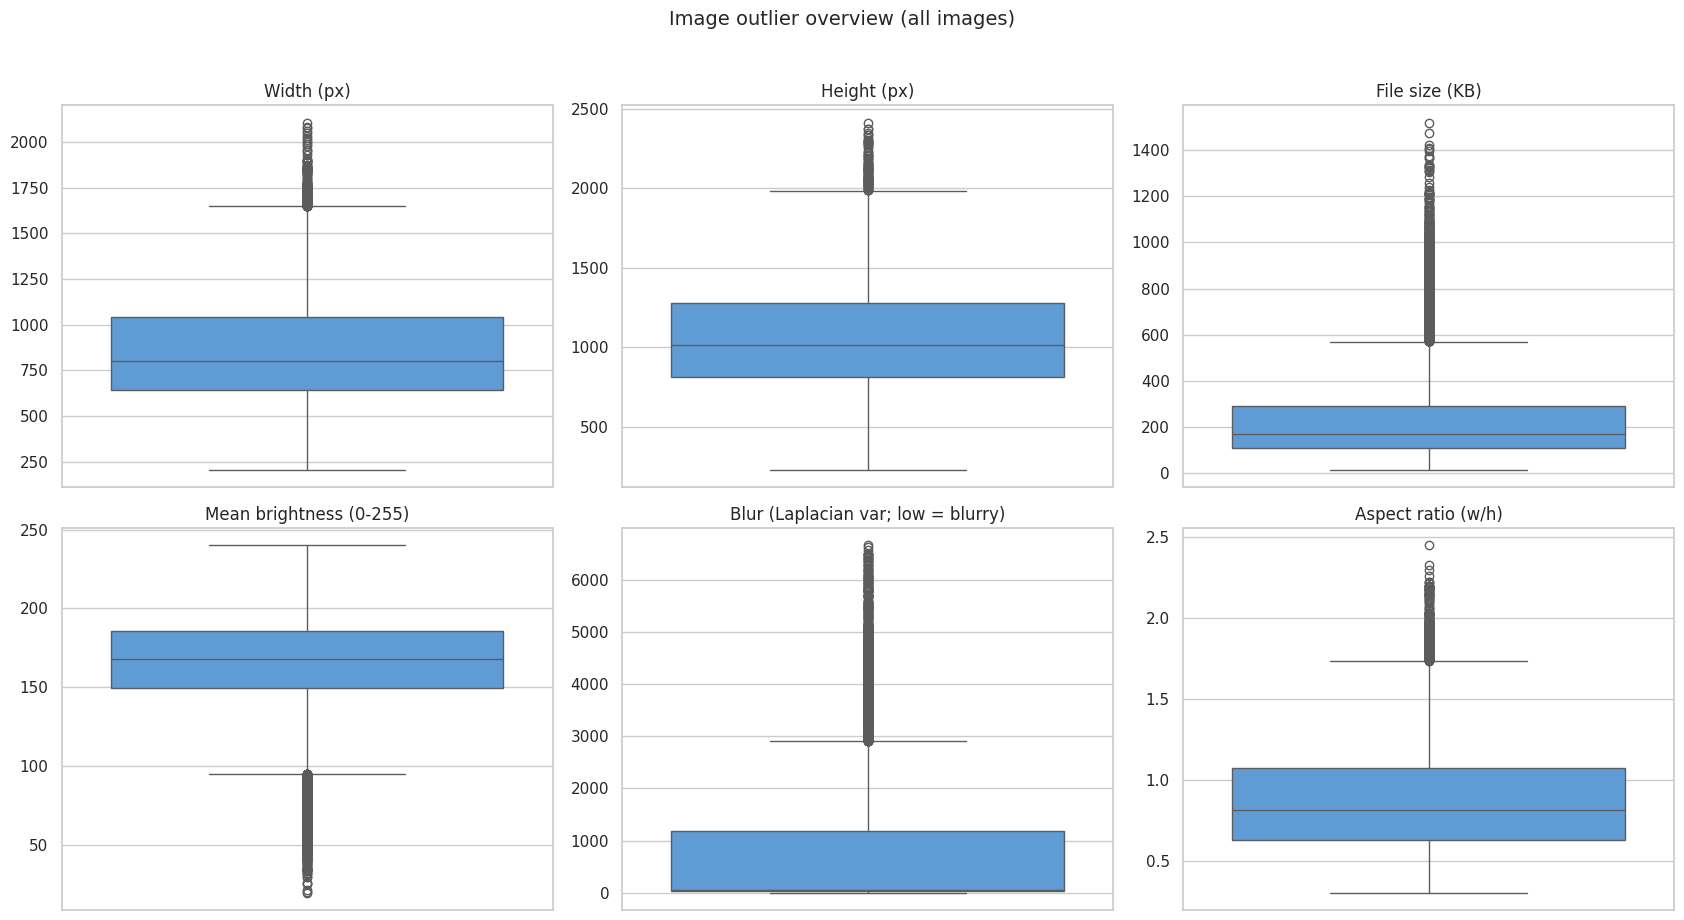

In [19]:
ok['aspect'] = ok['width'] / ok['height']
ok['area_mpx'] = ok['width'] * ok['height'] / 1e6

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col, ttl in zip(axes.ravel(),
        ['width', 'height', 'size_kb', 'brightness', 'blur', 'aspect'],
        ['Width (px)', 'Height (px)', 'File size (KB)', 'Mean brightness (0-255)', 'Blur (Laplacian var; low = blurry)', 'Aspect ratio (w/h)']):
    sns.boxplot(y=ok[col], ax=ax, color='#4C9BE8'); ax.set_title(ttl); ax.set_ylabel('')
plt.suptitle('Image outlier overview (all images)', y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig(os.path.join(IMG_OUT, '01_image_outlier_boxplots.png'), dpi=130, bbox_inches='tight'); plt.show()

In [20]:
def iqr_flag(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

for col in ['width', 'height', 'size_kb', 'brightness', 'blur']:
    ok['out_' + col] = ok.groupby('label')[col].transform(lambda s: iqr_flag(s))
ok['n_outlier_flags'] = ok[[c for c in ok.columns if c.startswith('out_')]].sum(axis=1)
print(ok[[c for c in ok.columns if c.startswith('out_') and c != 'out_']].sum())

# Extreme: near-blank images (almost no contrast)
ok['near_blank'] = (ok['contrast'] < 5)
print('\nNear-blank images (contrast < 5):', ok['near_blank'].sum())
log('outliers', 'IQR outliers on any image statistic (any flag)', (ok['n_outlier_flags'] > 0).sum(), 'flag only')
log('outliers', 'near-blank images (contrast < 5)', ok['near_blank'].sum(), 'drop')

out_width         1955
out_height        1627
out_size_kb       1688
out_brightness     303
out_blur          2042
dtype: int64

Near-blank images (contrast < 5): 0


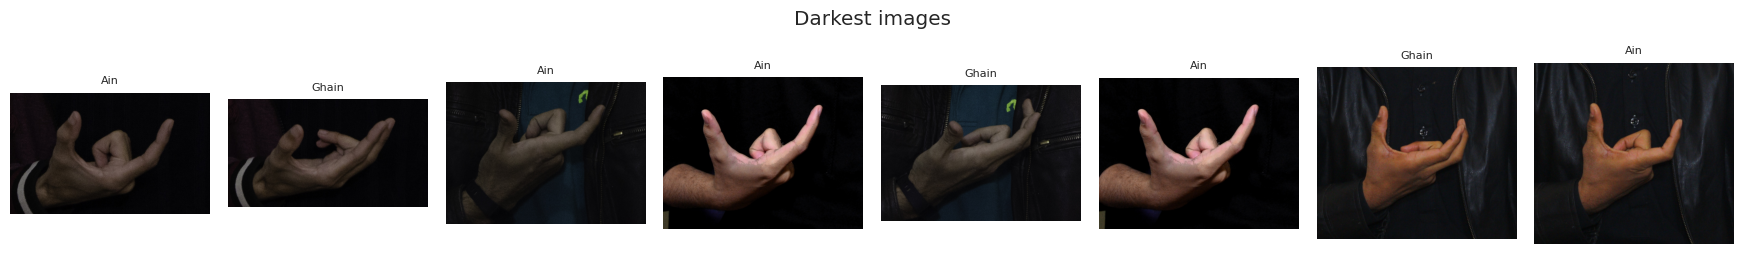

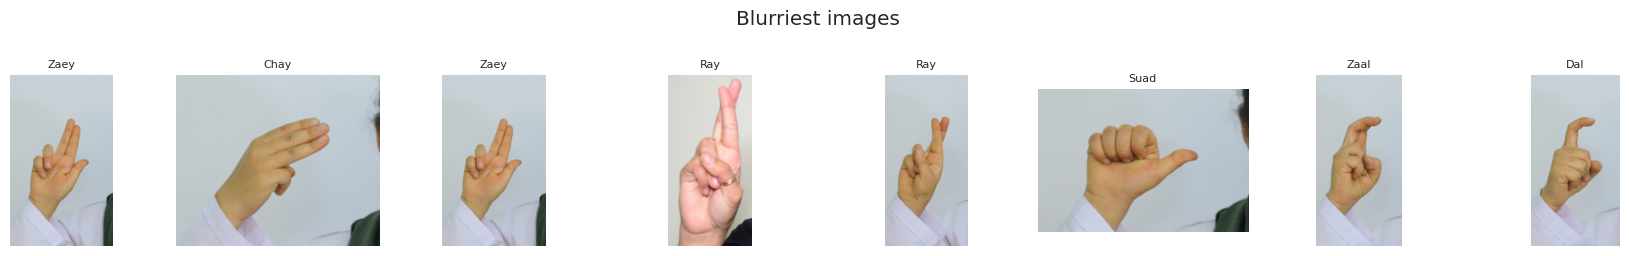

In [21]:
def show(df, title, n=8):
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for ax, (_, r) in zip(np.atleast_1d(axes), df.head(n).iterrows()):
        ax.imshow(cv2.cvtColor(cv2.imread(r['path']), cv2.COLOR_BGR2RGB)); ax.axis('off'); ax.set_title(r['label'], fontsize=8)
    plt.suptitle(title); plt.tight_layout(); return fig

f1 = show(ok.sort_values('brightness').head(8), 'Darkest images'); plt.savefig(os.path.join(IMG_OUT, '02_darkest_images.png'), dpi=120, bbox_inches='tight'); plt.show()
f2 = show(ok.sort_values('blur').head(8), 'Blurriest images'); plt.savefig(os.path.join(IMG_OUT, '03_blurriest_images.png'), dpi=120, bbox_inches='tight'); plt.show()

## 8. Videos (the 4 dynamic signs)
For each video: can it be opened, frame count, fps, resolution, duration, and first/last frame readable. Exact duplicates via MD5.

In [22]:
def analyze_video(path):
    out = {'path': path, 'corrupt': False, 'error': ''}
    try:
        with open(path, 'rb') as f:
            h = hashlib.md5()
            for chunk in iter(lambda: f.read(1 << 20), b''):
                h.update(chunk)
        out['md5'] = h.hexdigest()
        out['size_kb'] = os.path.getsize(path) / 1024
        cap = cv2.VideoCapture(path)
        if not cap.isOpened():
            raise ValueError('cannot open video')
        n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS)
        out.update(frames=n, fps=fps, width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                   height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), duration_s=(n / fps if fps else np.nan))
        ok1, _ = cap.read()
        cap.set(cv2.CAP_PROP_POS_FRAMES, max(n - 1, 0)); ok2, _ = cap.read()
        cap.release()
        if not (ok1 and ok2):
            raise ValueError('first/last frame unreadable')
    except Exception as e:
        out['corrupt'] = True; out['error'] = str(e)[:100]
    return out

vid_paths = meta.loc[meta['media_type'] == 'video', 'path'].tolist()
with ThreadPoolExecutor(max_workers=4) as ex:
    vid_stats = pd.DataFrame(list(tqdm(ex.map(analyze_video, vid_paths), total=len(vid_paths))))
vm = meta.merge(vid_stats.drop(columns=['corrupt', 'error']), on='path').merge(vid_stats[['path', 'corrupt', 'error']], on='path')
print('Videos:', len(vm), '| corrupt:', vm['corrupt'].sum(), '| exact duplicates:', vm.duplicated('md5').sum())
print('Classes with videos:', vm['label'].value_counts().to_dict())
vm[['frames', 'fps', 'duration_s', 'width', 'height', 'size_kb']].describe().round(2)

  0%|          | 0/393 [00:00<?, ?it/s]

Videos: 393 | corrupt: 0 | exact duplicates: 0
Classes with videos: {'Alifmad': 105, 'Aray': 102, 'Jeem': 99, '2-Hay': 87}


,frames,fps,duration_s,width,height,size_kb
count,393.00,393.0,393.00,393.0,393.0,393.00
mean,57.70,30.0,1.92,1920.0,1080.0,1414.72
std,17.64,0.0,0.59,0.0,0.0,598.55
min,13.00,30.0,0.43,1920.0,1080.0,346.20
25%,46.00,30.0,1.53,1920.0,1080.0,960.31
50%,55.00,30.0,1.83,1920.0,1080.0,1345.61
75%,70.00,30.0,2.33,1920.0,1080.0,1736.83
max,118.00,30.0,3.93,1920.0,1080.0,3848.33


Folders mixing images and videos: []
Dynamic classes: ['2-Hay', 'Alifmad', 'Aray', 'Jeem']


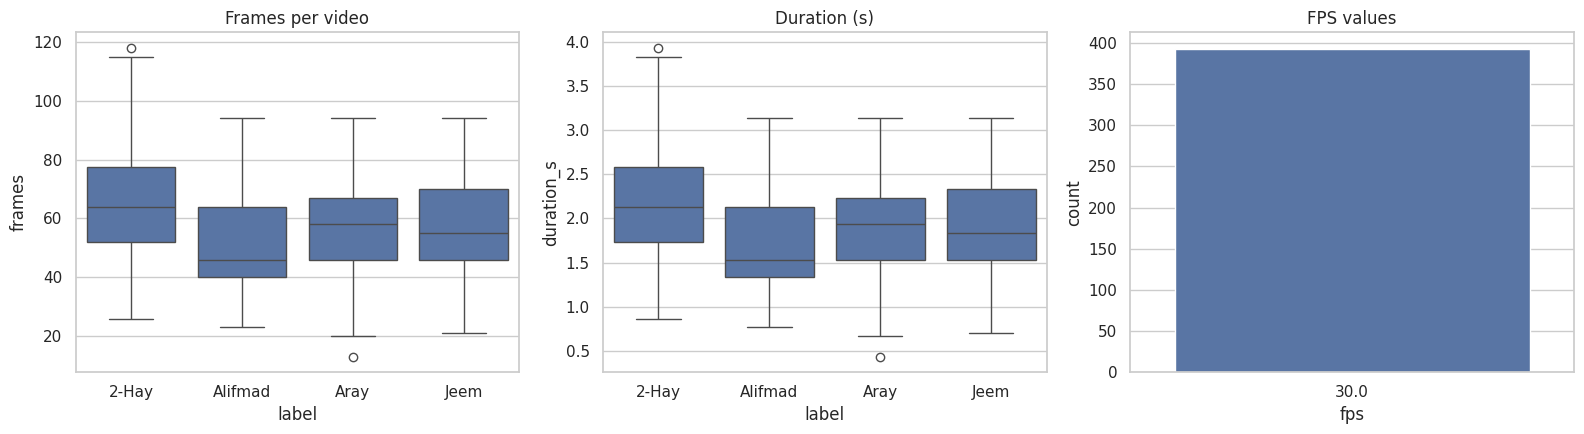

In [23]:
# Check if any class folders mix images and videos
mix = meta.groupby('label')['media_type'].nunique()
print('Folders mixing images and videos:', list(mix[mix > 1].index))
DYNAMIC = sorted(vm['label'].unique()); print('Dynamic classes:', DYNAMIC)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=vm, x='label', y='frames', ax=axes[0]); axes[0].set_title('Frames per video')
sns.boxplot(data=vm, x='label', y='duration_s', ax=axes[1]); axes[1].set_title('Duration (s)')
sns.countplot(data=vm, x='fps', ax=axes[2]); axes[2].set_title('FPS values')
plt.tight_layout(); plt.savefig(os.path.join(IMG_OUT, '04_video_outliers.png'), dpi=130, bbox_inches='tight'); plt.show()

vm['out_frames'] = vm.groupby('label')['frames'].transform(lambda s: iqr_flag(s))
log('videos', 'corrupt / unreadable videos', vm['corrupt'].sum(), 'drop')
log('videos', 'exact duplicate videos', vm.duplicated('md5').sum(), 'drop (keep first)')
log('videos', 'frame-count outliers (IQR within class)', vm['out_frames'].sum(), 'flag only')

In [35]:
# Keep properly-named files when removing duplicates
ok = ok.sort_values('name_matched', ascending=False, kind='stable').reset_index(drop=True)

# Cross-class duplicates: drop only the copy whose filename class contradicts its folder
multi_label = ok.groupby('md5')['label'].transform('nunique') > 1
ok['cross_class_dup'] = multi_label & ok['label_conflict']

# Exact duplicates among the remaining files (first = properly-named one)
ok['exact_dup'] = False
rest = ok[~ok['cross_class_dup']]
ok.loc[rest.index[rest.duplicated('md5', keep='first')], 'exact_dup'] = True

print('Exact duplicates to drop:', ok['exact_dup'].sum())
print('Cross-class (mislabeled copy) to drop:', ok['cross_class_dup'].sum())

for e in cleaning_log:
    if e['issue'] == 'exact duplicate images (extra copies)':
        e['count'] = int(ok['exact_dup'].sum())
        e['action'] = 'drop (keep first; properly named file preferred)'
    if e['issue'] == 'files in cross-class exact duplicates':
        e['count'] = int(ok['cross_class_dup'].sum())
        e['action'] = 'drop only the mislabeled copy (in Ghain folder)'

Exact duplicates to drop: 1485
Cross-class (mislabeled copy) to drop: 20


## 9. Apply decisions and save cleaned metadata
- `DROP_LABEL_CONFLICTS` – drop files whose filename class contradicts the folder (likely mislabels).

In [36]:
DROP_LABEL_CONFLICTS = True

# ---- images ----
imgs = ok.merge(img_stats[['path', 'corrupt']], on='path')
imgs['drop_reason'] = ''
imgs.loc[imgs['size_bytes'] == 0, 'drop_reason'] = 'zero_byte'
imgs.loc[imgs['corrupt'], 'drop_reason'] = 'corrupt'
imgs.loc[(imgs['drop_reason'] == '') & imgs['near_blank'], 'drop_reason'] = 'near_blank'
imgs.loc[(imgs['drop_reason'] == '') & imgs['cross_class_dup'], 'drop_reason'] = 'cross_class_duplicate'
imgs.loc[(imgs['drop_reason'] == '') & imgs['exact_dup'], 'drop_reason'] = 'exact_duplicate'
if DROP_LABEL_CONFLICTS:
    imgs.loc[(imgs['drop_reason'] == '') & imgs['label_conflict'], 'drop_reason'] = 'label_conflict'

# ---- videos ----
vm['drop_reason'] = ''
vm.loc[vm['corrupt'], 'drop_reason'] = 'corrupt'
vm.loc[(vm['drop_reason'] == '') & vm.duplicated('md5'), 'drop_reason'] = 'exact_duplicate'

print('Images dropped by reason:'); print(imgs['drop_reason'].value_counts())
print('\nVideos dropped by reason:'); print(vm['drop_reason'].value_counts())

Images dropped by reason:
drop_reason
                         21360
exact_duplicate           1485
cross_class_duplicate       20
Name: count, dtype: int64

Videos dropped by reason:
drop_reason
    393
Name: count, dtype: int64


In [37]:
keep_img = imgs[imgs['drop_reason'] == ''].copy()
keep_vid = vm[vm['drop_reason'] == ''].copy()
keep_img['dynamic'] = False; keep_vid['dynamic'] = True

cols = ['rel_path', 'label', 'media_type', 'dynamic', 'subject', 'is_generated', 'ext', 'size_kb', 'width', 'height',
        'channels', 'brightness', 'contrast', 'blur', 'md5']
vcols = ['frames', 'fps', 'duration_s']
clean = pd.concat([keep_img.reindex(columns=cols + ['dhash_group_size', 'n_outlier_flags']),
                   keep_vid.reindex(columns=cols + vcols + ['out_frames'])], ignore_index=True)
clean.to_csv(os.path.join(OUT, 'clean_metadata.csv'), index=False)

print('Images: raw', len(imgs), '-> clean', len(keep_img))
print('Videos: raw', len(vm), '-> clean', len(keep_vid))
print('Classes remaining:', clean['label'].nunique())
summary = pd.DataFrame(cleaning_log); summary.to_csv(os.path.join(OUT, 'cleaning_summary.csv'), index=False)
summary

Images: raw 22865 -> clean 21360
Videos: raw 393 -> clean 393
Classes remaining: 40


,step,issue,count,action
0,missing,zero-byte files,0,drop
1,missing,empty class folders,0,none needed
2,format,mixed-case extensions (.JPG vs .jpg),1678,normalised in metadata column `ext`; raw files...
3,format,filename class differs from folder class,20,flagged (see decision cell below)
4,corrupt,unreadable images,0,drop
5,duplicates,exact duplicate images (extra copies),1485,drop (keep first; properly named file preferred)
6,duplicates,files in cross-class exact duplicates,20,drop only the mislabeled copy (in Ghain folder)
7,duplicates,"near-duplicates (same class, same dhash)",6674,flag only (augmentation copies)
8,outliers,IQR outliers on any image statistic (any flag),5586,flag only
9,outliers,near-blank images (contrast < 5),0,drop


In [38]:
# Class counts before vs after cleaning
before = meta.groupby('label').size().rename('before')
after = clean.groupby('label').size().rename('after')
cmp = pd.concat([before, after], axis=1).fillna(0).astype(int); cmp['removed'] = cmp['before'] - cmp['after']
cmp.sort_values('removed', ascending=False).head(15)

,before,after,removed
label,,,
Gaaf,1152,568,584
Ghain,606,560,46
Seen,684,645,39
Meem,586,547,39
Ain,586,548,38
Zuad,586,549,37
Fay,586,550,36
Suad,684,651,33
Nuun,581,549,32


## 10. Download outputs
In the Colab file panel, download `outputs/clean_metadata.csv`, `outputs/cleaning_summary.csv` and the 4 PNGs in `outputs/images/`.

In [39]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)

hdr('Raw totals')
print('Total files:', len(meta), '| images:', (meta['media_type'] == 'image').sum(), '| videos:', (meta['media_type'] == 'video').sum())

hdr('Folders containing more than one filename-class')
print(multi.to_string() if len(multi) else 'None')

hdr('Dominant filename-class per folder')
print(dominant[['name_in_file', 'n', 'share']].round(3).to_string())
print('\nFolders with NO clear dominant class:', list(unclear.index))
print('Label-conflict files flagged:', meta['label_conflict'].sum())

hdr('Gaaf investigation')
print('Gaaf files:', len(g))
print('\nFilename classes inside Gaaf:'); print(g['name_in_file'].value_counts().head(10).to_string())
print('\nGenerated vs original:'); print(g['is_generated'].value_counts().to_string())
print('\nTop subjects:'); print(g['subject'].value_counts().head(10).to_string())
print('\nGaaf exact-duplicate share:', ok[ok['label'] == 'Gaaf']['exact_dup'].mean().round(3))
print('Kaf (typical): generated share =', t['is_generated'].mean().round(3), '| subjects =', t['subject'].nunique())
print('Gaaf: generated share =', g['is_generated'].mean().round(3), '| subjects =', g['subject'].nunique())

hdr('Corrupt, duplicates')
print('Corrupt images:', img_stats['corrupt'].sum())
print('Exact duplicate images (extra copies):', ok['exact_dup'].sum())
print('Files in cross-class exact duplicates:', ok['cross_class_dup'].sum())
print('Cross-class examples:'); print(cross_files.head(10).to_string())
print('\nExact duplicates by class (top 10):'); print(ok[ok['exact_dup']].groupby('label').size().sort_values(ascending=False).head(10).to_string())
print('\nNear-duplicates flagged:', len(near), '| generated:', near['is_generated'].sum(), '| original:', (~near['is_generated']).sum())

hdr('Image outliers')
print('Distinct (width, height) sizes:', img_stats.groupby(['width', 'height']).ngroups)
print(img_stats.groupby(['width', 'height']).size().sort_values(ascending=False).head(5).to_string())
print('\nIQR flags per statistic:'); print(ok[[c for c in ok.columns if c.startswith('out_')]].sum().to_string())
print('Near-blank images:', ok['near_blank'].sum())
print('\nImage stats summary:'); print(ok[['width', 'height', 'size_kb', 'brightness', 'contrast', 'blur']].describe().round(2).to_string())

hdr('Videos')
print('Videos:', len(vm), '| corrupt:', vm['corrupt'].sum(), '| exact duplicates:', vm.duplicated('md5').sum())
print('Dynamic classes:', DYNAMIC)
print('Folders mixing images and videos:', list(mix[mix > 1].index))
print(vm.groupby('label')[['frames', 'fps', 'duration_s']].agg(['count', 'mean', 'min', 'max']).round(2).to_string())
print('Frame-count outliers:', vm['out_frames'].sum())

hdr('Drop reasons')
print('Images:'); print(imgs['drop_reason'].replace('', 'kept').value_counts().to_string())
print('\nVideos:'); print(vm['drop_reason'].replace('', 'kept').value_counts().to_string())

hdr('Final counts')
print('Images: raw', len(imgs), '-> clean', len(keep_img))
print('Videos: raw', len(vm), '-> clean', len(keep_vid))
print('Classes remaining:', clean['label'].nunique())

hdr('Cleaning summary table')
print(summary.to_string(index=False))

hdr('Class counts before vs after (all 40 classes)')
print(cmp.sort_values('removed', ascending=False).to_string())


Raw totals
Total files: 23258 | images: 22865 | videos: 393

Folders containing more than one filename-class
    label name_in_file    n     share
12  Ghain      26ghain  586  0.966997
13  Ghain       30gaaf   20  0.033003

Dominant filename-class per folder
         name_in_file    n  share
label                            
1-Hay           10hay  659  1.000
Ain             25ain  586  1.000
Alif           02alif  660  1.000
Bay             03bay  690  1.000
Byeh           40byeh  562  1.000
Chay           09chay  628  1.000
Cyeh           39cyeh  562  1.000
Daal           13daal  659  1.000
Dal             12dal  584  1.000
Dochahay   37dochahay  561  1.000
Fay             27fay  586  1.000
Gaaf           30gaaf  586  1.000
Hamza         38hamza  561  1.000
Meem           32meem  586  1.000
Kaf             28kaf  586  1.000
Khay           11khay  634  1.000
Kiaf           29kiaf  586  1.000
Nuun           33nuun  581  1.000
Lam             31lam  586  1.000
Pay             04pay  665

In [40]:
imgs_clean = clean[clean['media_type'] == 'image']
print('Clean images:', len(imgs_clean))
print('Gaaf after cleaning:', (imgs_clean['label'] == 'Gaaf').sum())
print('Images with missing subject ID:', imgs_clean['subject'].isna().sum())
print('Images with missing subject ID:', clean.loc[clean['media_type']=='image','subject'].isna().sum())

Clean images: 21360
Gaaf after cleaning: 568
Images with missing subject ID: 0
Images with missing subject ID: 0
